# 20. Infrasound clipping: which sensors saturated, when, and for how long

The Gem infrasound loggers digitize at 16 bits. Close to the pad the launch exceeded that range.
While a Gem is overflowing, consecutive raw samples jump by more than 20,000 counts (wraparound)
and the baseline then walks off by up to ~2 million counts. This notebook:

1. finds clusters of large one-sample jumps (>20,000 counts, clustered with a 2 s gap, padded 0.25 s)
   in every Gem channel's raw counts and classifies them. A **true overflow** leaves a persistent
   baseline step (>32,768 counts; observed 6.6e4-2e6). A **shock** (steep crackle front, e.g. -71 to
   +122 Pa in 4 ms at B29) jumps just as far in one sample but leaves no step and is real signal.
   A single jump with a persistent step is a **baseline reset**. Overflow and resets are masked;
   shocks are not;
2. checks the Centaur channels (24-bit; Trillium DH? and infraBSU DD?) against their full scale;
3. **validates** the interval definition at B01, where an overflowing Gem (`HDI`) sits next to an
   unclipped infraBSU (`DD0`): outside the clipped interval the two should agree;
4. estimates the pressure at which a Gem starts to wrap.

Clipped channels are **kept** in later analyses; notebooks 40, 42 and 50 mask only the clipped
intervals using `cfg.stream_clip_intervals` / `cfg.clip_mask`.

Outputs (`cfg.OUT_DIR`): `gem_clip_intervals.csv`, `gem_clip_summary.csv`, `centaur_full_scale.csv`,
`clipping_timeline.png`, `clipping_validation_B01.png`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gemlog

import artemis2_config as cfg

L = cfg.LAUNCHTIME
OUT = cfg.OUT_DIR / "20_infrasound_clipping"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.grid': True, 'grid.color': '#dddddd', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False})
stations = cfg.station_table()
client = cfg.sds_client()
print('output:', OUT)

output: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/Artemis2/20_infrasound_clipping


## 1. Gem clipped intervals from raw counts

In [2]:
st_gem = cfg.get_group_stream('BSU', client).merge()
clusters = {tr.id: cfg.gem_jump_clusters(tr) for tr in st_gem}
intervals = cfg.stream_clip_intervals(st_gem)          # overflow + reset only

rows, summary = [], []
for tr in sorted(st_gem, key=lambda t: t.id):
    sta = tr.stats.station
    dist = stations.distance_km.get(sta, np.nan)
    for c in clusters[tr.id]:
        rows.append(dict(seed_id=tr.id, distance_km=dist, kind=c['kind'], start_s=c['t0'] - L,
                         end_s=c['t1'] - L, duration_s=c['t1'] - c['t0'], n_jumps=c['n_jumps'],
                         baseline_step_counts=c['step']))
    ov = [c for c in clusters[tr.id] if c['kind'] == 'overflow']
    summary.append(dict(seed_id=tr.id, distance_km=dist, azimuth_deg=stations.azimuth_deg.get(sta, np.nan),
                        overflow=bool(ov),
                        first_overflow_s=(ov[0]['t0'] - L) if ov else np.nan,
                        last_overflow_s=(ov[-1]['t1'] - L) if ov else np.nan,
                        overflow_total_s=sum(c['t1'] - c['t0'] for c in ov),
                        n_resets=sum(c['kind'] == 'reset' for c in clusters[tr.id]),
                        n_shock_jumps=sum(c['n_jumps'] for c in clusters[tr.id] if c['kind'] == 'shock')))
clip_iv = pd.DataFrame(rows)
clip_sum = pd.DataFrame(summary).sort_values('distance_km')
clip_iv.to_csv(OUT / 'gem_clip_intervals.csv', index=False)
clip_sum.to_csv(OUT / 'gem_clip_summary.csv', index=False)
with pd.option_context('display.float_format', '{:.2f}'.format, 'display.width', 200):
    display(clip_sum)
    display(clip_iv)

,seed_id,distance_km,azimuth_deg,overflow,first_overflow_s,last_overflow_s,overflow_total_s,n_resets,n_shock_jumps
5,1R.B14..HDF,0.74,41.39,True,2.38,31.02,28.64,0,0
6,1R.B14..HDI,0.74,41.39,True,2.14,31.02,28.88,0,0
0,1R.B01..HDI,1.53,115.01,True,12.74,35.36,22.62,0,0
1,1R.B03..HDI,1.75,351.04,True,16.27,30.69,14.42,1,0
4,1R.B12..HDF,2.65,256.59,True,23.05,36.61,13.56,0,1
2,1R.B07..HDF,3.42,130.36,False,NaN,NaN,0.00,0,15
3,1R.B07.10.HDF,3.42,130.36,True,26.01,41.93,15.92,0,4
13,1R.B24..HDI,5.53,200.73,False,NaN,NaN,0.00,0,0
12,1R.B24..HDF,5.53,200.73,False,NaN,NaN,0.00,0,0
11,1R.B23..HDF,5.54,166.67,False,NaN,NaN,0.00,0,1


,seed_id,distance_km,kind,start_s,end_s,duration_s,n_jumps,baseline_step_counts
0,1R.B01..HDI,1.53,overflow,12.74,35.36,22.62,274,-1901139.00
1,1R.B03..HDI,1.75,overflow,16.27,30.69,14.42,87,-394351.00
2,1R.B03..HDI,1.75,reset,316.82,317.33,0.51,1,393043.00
3,1R.B07..HDF,3.42,shock,26.19,27.84,1.65,4,-263.00
4,1R.B07..HDF,3.42,shock,32.08,33.25,1.17,2,1521.00
5,1R.B07..HDF,3.42,shock,34.95,40.14,5.19,7,-945.00
6,1R.B07..HDF,3.42,shock,45.05,45.56,0.51,1,11.00
7,1R.B07..HDF,3.42,shock,49.87,50.38,0.51,1,713.00
8,1R.B07.10.HDF,3.42,overflow,26.01,41.93,15.92,37,-66197.00
9,1R.B07.10.HDF,3.42,shock,44.74,45.57,0.83,2,601.00


## 2. Centaur channels against full scale

The Centaur is 24-bit (±8,388,608 counts). At the 40 Vpp (Trillium) and 1 Vpp (infraBSU) input ranges
full scale is ≈28 mm/s and ≈11.4 kPa.

In [3]:
st_cen = cfg.get_group_stream('USF', client).merge()
if not st_cen.select(id='1R.B29.00.DHZ'):
    st_cen += cfg.read_restored('1R.B29.00.DHZ')
FULL = 2 ** 23
rows = []
for tr in st_cen.select(channel='D[DH]?'):
    d = tr.slice(L - 30, L + 300).data
    if not len(d):
        continue
    pre = np.median(tr.slice(L - 1500, L - 60).data)
    rows.append(dict(seed_id=tr.id, max_abs_counts=int(np.abs(d).max()),
                     percent_of_full_scale=100 * np.abs(d).max() / FULL,
                     prelaunch_offset_percent=100 * pre / FULL))
cen = pd.DataFrame(rows).sort_values('percent_of_full_scale', ascending=False)
cen.to_csv(OUT / 'centaur_full_scale.csv', index=False)
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(cen)
print('A large pre-launch offset (DC level as % of full scale) on a Trillium channel means the sensor mass')
print('is off-centre; that channel has little headroom and its long-period output is unreliable.')

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/ksclib/src/ksclib/data.py:32: UserWarning: SKIPPED unreadable SDS file /Volumes/KSCGTdownld/SDS/2026/1R/B29/DHZ.D/1R.B29.00.DHZ.D.2026.091 (InternalMSEEDParseTimeError)
  warnings.warn(f"SKIPPED unreadable SDS file {path} ({type(exc).__name__})")


,seed_id,max_abs_counts,percent_of_full_scale,prelaunch_offset_percent
16,1R.B05.00.DH2,8250162,98.350,-98.305
15,1R.B05.00.DH1,6588217,78.538,74.246
5,1R.B01.00.DHZ,826420,9.852,0.095
4,1R.B01.00.DH2,671250,8.002,0.031
12,1R.B05.00.DD0,601682,7.173,3.723
3,1R.B01.00.DH1,591107,7.047,0.019
17,1R.B05.00.DHZ,470263,5.606,0.535
0,1R.B01.00.DD0,372734,4.443,0.039
22,1R.B29.00.DH2,365130,4.353,-0.049
1,1R.B01.00.DD1,339098,4.042,0.043


A large pre-launch offset (DC level as % of full scale) on a Trillium channel means the sensor mass
is off-centre; that channel has little headroom and its long-period output is unreliable.


## 3. Validation at B01: overflowing Gem HDI vs unclipped infraBSU DD0

/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


B01 HDI vs DD0 (1-20 Hz), 5-s windows outside the clipped interval: median cc 0.988, median RMS ratio 0.960
inside: median cc 0.000, median RMS ratio 0.003


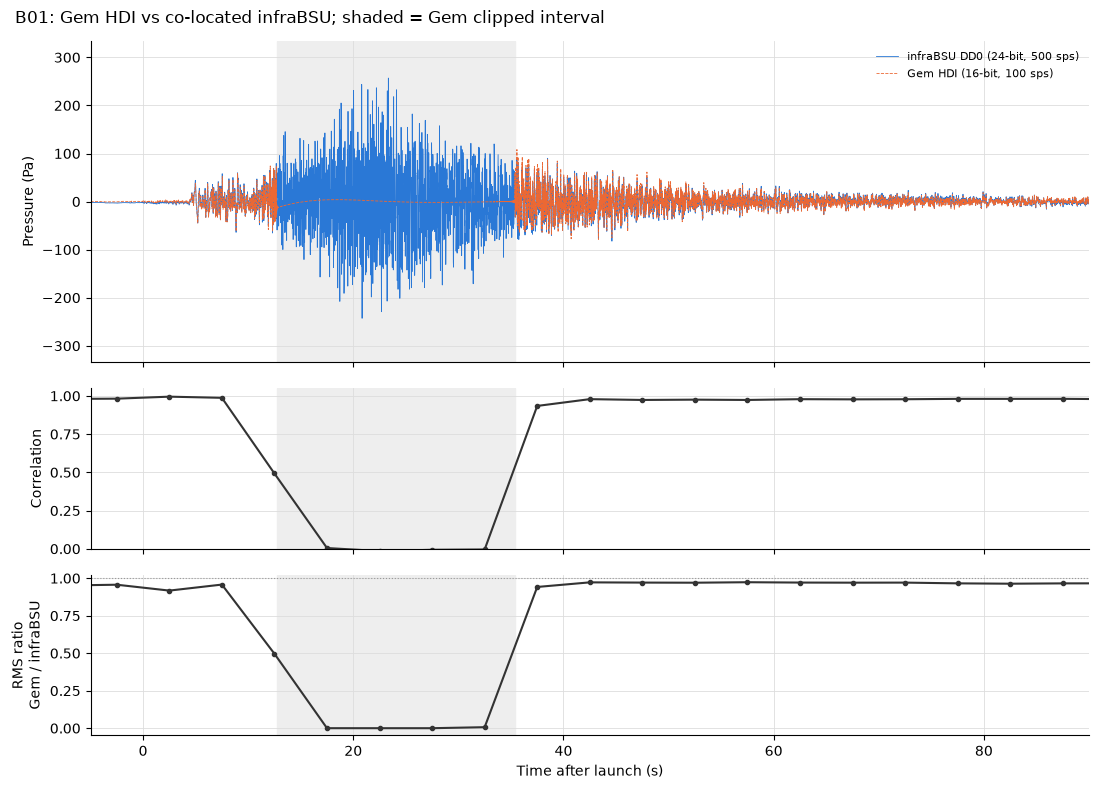

In [4]:
gem = cfg.instrument_correct(st_gem.select(id='1R.B01..HDI'))[0]
dd0 = cfg.instrument_correct(st_cen.select(id='1R.B01.00.DD0'))[0]
dd0.filter('lowpass', freq=40, corners=8, zerophase=True)
dd0.resample(100, no_filter=True)
band = (1.0, 20.0)
g_b, d_b = gem.copy(), dd0.copy()
for t in (g_b, d_b):
    t.filter('bandpass', freqmin=band[0], freqmax=band[1], zerophase=True)

WIN = 5.0
rows = []
for t0 in np.arange(-10, 300, WIN):
    a = g_b.slice(L + t0, L + t0 + WIN).data; b = d_b.slice(L + t0, L + t0 + WIN).data
    n = min(len(a), len(b)); a, b = a[:n], b[:n]
    rows.append(dict(t=t0 + WIN / 2, cc=np.corrcoef(a, b)[0, 1], rms_ratio=a.std() / b.std(),
                     dd0_peak_Pa=np.abs(b).max()))
val = pd.DataFrame(rows)
ivs = intervals['1R.B01..HDI']
outside = np.ones(len(val), bool)
for a, b in ivs:
    outside &= ~((val.t + WIN / 2 > a - L) & (val.t - WIN / 2 < b - L))
print(f"B01 HDI vs DD0 ({band[0]:g}-{band[1]:g} Hz), 5-s windows outside the clipped interval: "
      f"median cc {val.cc[outside].median():.3f}, median RMS ratio {val.rms_ratio[outside].median():.3f}")
print(f"inside: median cc {val.cc[~outside].median():.3f}, median RMS ratio {val.rms_ratio[~outside].median():.3f}")

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True, gridspec_kw=dict(height_ratios=[2, 1, 1]))
s1, s2 = gem.slice(L - 5, L + 90), dd0.slice(L - 5, L + 90)
ax[0].plot(s2.times() - 5, s2.data, color='#2a78d6', lw=0.6, label='infraBSU DD0 (24-bit, 500 sps)')
ax[0].plot(s1.times() - 5, s1.data, color='#eb6834', lw=0.6, ls='--', label='Gem HDI (16-bit, 100 sps)')
ax[0].set_ylim(1.3 * np.abs(s2.data).min() - 1.3 * np.abs(s2.data).max(), 1.3 * np.abs(s2.data).max())
ax[0].set_ylabel('Pressure (Pa)')
ax[0].legend(frameon=False, fontsize=8, loc='upper right')
ax[1].plot(val.t, val.cc, 'o-', color='#333333', ms=3)
ax[1].set(ylabel='Correlation', ylim=(0, 1.05))
ax[2].plot(val.t, val.rms_ratio, 'o-', color='#333333', ms=3)
ax[2].axhline(1, color='#999999', lw=0.8, ls=':')
ax[2].set(ylabel='RMS ratio\nGem / infraBSU', xlabel='Time after launch (s)', xlim=(-5, 90))
for a_ in ax:
    for a, b in ivs:
        a_.axvspan(a - L, b - L, color='#eeeeee', zorder=0)
fig.suptitle('B01: Gem HDI vs co-located infraBSU; shaded = Gem clipped interval', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'clipping_validation_B01.png', dpi=200)

## 4. Pressure at which the Gem starts to wrap

infraBSU pressure (full band) within ±0.05 s of the first few wraparound jumps of B01 HDI.

In [5]:
dd0_full = cfg.instrument_correct(st_cen.select(id='1R.B01.00.DD0'))[0]
raw = st_gem.select(id='1R.B01..HDI')[0]
d = raw.data.astype(np.int64)
k = np.flatnonzero(np.abs(np.diff(d)) > cfg.GEM_JUMP_COUNTS)
p_at_jump = [np.abs(dd0_full.slice(raw.stats.starttime + i * raw.stats.delta - 0.05,
                                   raw.stats.starttime + i * raw.stats.delta + 0.05).data).max() for i in k[:10]]
print('infraBSU |p| at first 10 jumps (Pa):', np.round(p_at_jump, 0))
print(f'=> Gem (high gain) clips at roughly {np.min(p_at_jump):.0f}-{np.median(p_at_jump):.0f} Pa')

/opt/anaconda3/envs/flovopy_plus/lib/python3.12/site-packages/obspy/core/inventory/response.py:1089: UserWarning: ObsPy can not map unit 'Pa' to displacement, velocity, or acceleration - evalresp should still work and just use the response as is. This might not be covered by tests, though, so proceed with caution and report any unexpected behavior.
  warnings.warn(msg)


infraBSU |p| at first 10 jumps (Pa): [114. 117. 117. 161. 161. 181. 102. 135. 139. 139.]
=> Gem (high gain) clips at roughly 102-137 Pa


## 5. Timeline figure

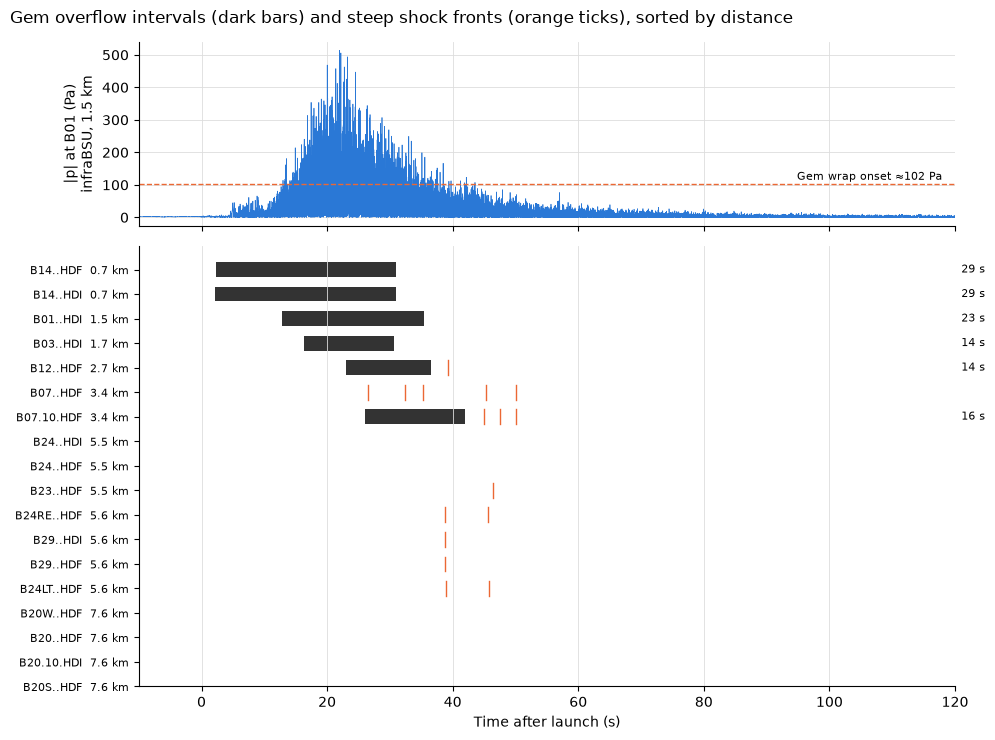

In [6]:
gem_rows = clip_sum[clip_sum.distance_km.notna()].sort_values('distance_km', ascending=False)
fig, ax = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, gridspec_kw=dict(height_ratios=[1, 2.4]))
env = np.abs(dd0_full.slice(L - 10, L + 120).data)
tt = dd0_full.slice(L - 10, L + 120).times() - 10
ax[0].plot(tt, env, color='#2a78d6', lw=0.5)
ax[0].axhline(np.min(p_at_jump), color='#eb6834', ls='--', lw=1)
ax[0].text(118, np.min(p_at_jump) * 1.05, f'Gem wrap onset ≈{np.min(p_at_jump):.0f} Pa', ha='right',
           va='bottom', fontsize=8)
ax[0].set(ylabel='|p| at B01 (Pa)\ninfraBSU, 1.5 km')
for y, (_, r) in enumerate(gem_rows.iterrows()):
    for c in clusters[r.seed_id]:
        if c['kind'] == 'shock':
            ax[1].plot([c['t0'] - L + 0.25] * 2, [y - 0.3, y + 0.3], color='#eb6834', lw=1)
        else:
            ax[1].barh(y, c['t1'] - c['t0'], left=c['t0'] - L, height=0.6, color='#333333')
    lab = f"{r.overflow_total_s:.0f} s" if r.overflow else ''
    ax[1].text(121, y, lab, va='center', fontsize=8)
ax[1].set_yticks(range(len(gem_rows)))
ax[1].set_yticklabels([f"{s.replace('1R.', '')}  {d:.1f} km" for s, d in zip(gem_rows.seed_id, gem_rows.distance_km)],
                      fontsize=8)
ax[1].set(xlabel='Time after launch (s)', xlim=(-10, 120))
ax[1].grid(axis='y', visible=False)
fig.suptitle('Gem overflow intervals (dark bars) and steep shock fronts (orange ticks), sorted by distance', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(OUT / 'clipping_timeline.png', dpi=200)

## Notes

* Distances use the station-table coordinates; Gem 363 (`1R.UNK..HD1`) has no table entry.
* A clipped interval ends at the last wraparound jump. Data after it are usable once the baseline
  offset is removed by the 0.05 Hz high-pass in the Gem correction (validated at B01).
* B03 HDI has a single baseline reset at ~317 s that undoes its overflow offset; it is masked.
* Shock fronts are real signal and are kept. They are not resolved at 100 sps (see notebook 45).
* A Gem that is not flagged can still underestimate peaks that approach its range; compare
  B07 HDF (raw peak ~30,000 counts) with its neighbour B07.10 HDF.